In [1]:
import numpy as np
from sklearn.datasets import load_iris
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb
import pingouin as pg
from scipy import stats

In [2]:
iris = load_iris()
iris_pd = pd.DataFrame(data=iris.data, columns=iris.feature_names)


In [3]:
display(iris_pd.head())
display(iris_pd.info())
display(iris_pd.describe())
display(iris_pd.shape)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB


None

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


(150, 4)

## Часть 1. Разведочный анализ данных (EDA)

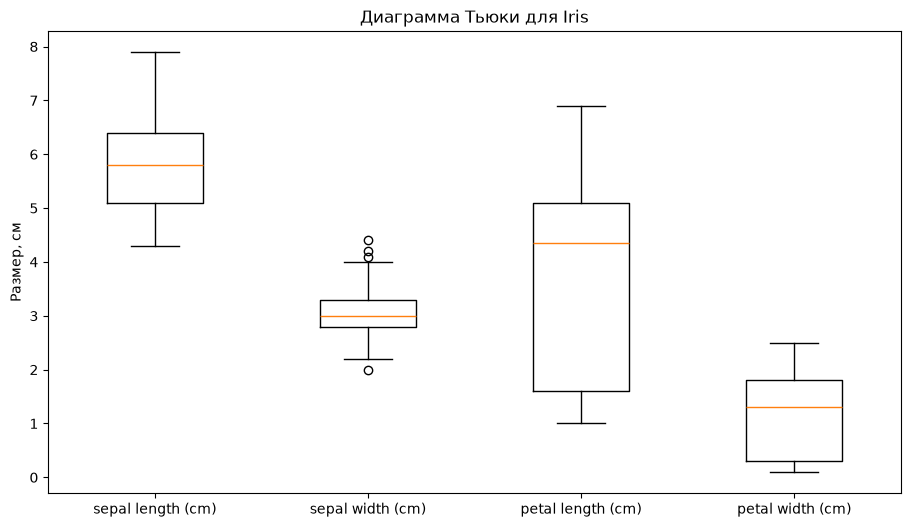

In [4]:
plt.figure(figsize=(11, 6))

plt.boxplot(iris_pd.to_numpy(),tick_labels=iris_pd.columns)

plt.title("Диаграмма Тьюки для Iris")
plt.ylabel("Размер, см")
plt.show()

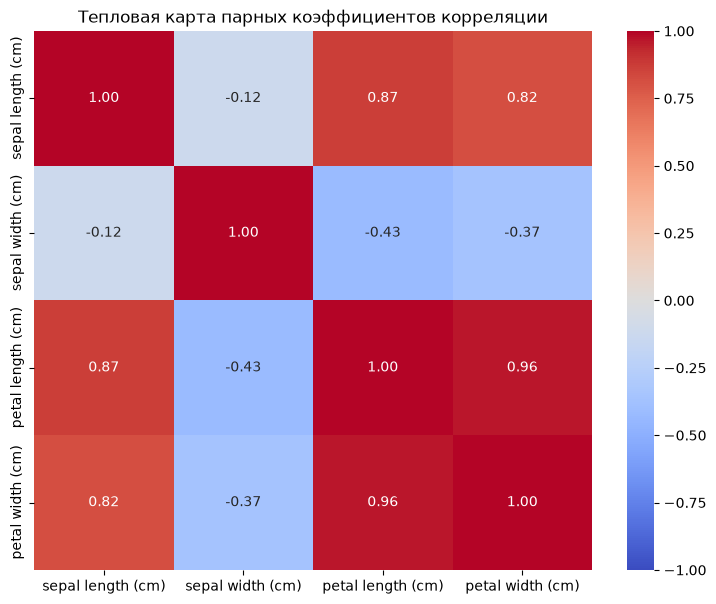

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.000000,-0.117570,0.871754,0.817941
sepal width (cm),-0.117570,1.000000,-0.428440,-0.366126
petal length (cm),0.871754,-0.428440,1.000000,0.962865
petal width (cm),0.817941,-0.366126,0.962865,1.000000


In [5]:
import seaborn as sns 
corr_matrix = iris_pd.corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot = True,fmt=".2f",cmap="coolwarm",  vmin=-1, vmax=1)
plt.title("Тепловая карта парных коэффициентов корреляции")
plt.show()
display(corr_matrix)

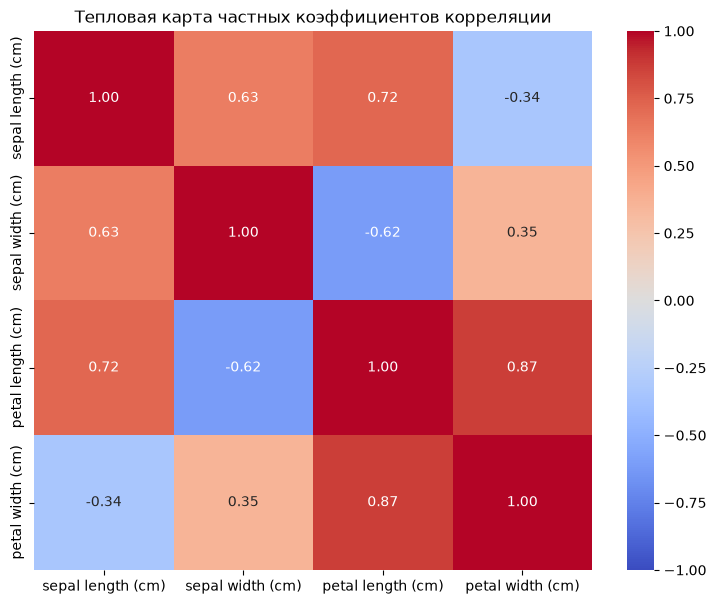

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.000000,0.628571,0.719066,-0.339617
sepal width (cm),0.628571,1.000000,-0.615292,0.352626
petal length (cm),0.719066,-0.615292,1.000000,0.870770
petal width (cm),-0.339617,0.352626,0.870770,1.000000


In [6]:
partial_corr_matrix = iris_pd.pcorr()
plt.figure(figsize=(9, 7))
sns.heatmap(partial_corr_matrix, annot = True,fmt=".2f",cmap="coolwarm",  vmin=-1, vmax=1, center = 0)
plt.title("Тепловая карта частных коэффициентов корреляции")
plt.show()
display(partial_corr_matrix)

In [7]:
difference = partial_corr_matrix - corr_matrix

print("Разница между частными и парными корреляциями:")
display(difference.round(3))

Разница между частными и парными корреляциями:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),0.000,0.746,-0.153,-1.158
sepal width (cm),0.746,0.000,-0.187,0.719
petal length (cm),-0.153,-0.187,0.000,-0.092
petal width (cm),-1.158,0.719,-0.092,0.000


In [8]:
print("Тест Колмогорова-Смирнова. Уровень значимости α = 0.05")

for col in iris_pd.columns:
    x = iris_pd[col]

    x_mean = np.mean(x)
    std = np.std(x, ddof=1)

    x_std = (x - x_mean) / std

    statistic, pvalue = stats.kstest(
        x_std, "norm", alternative="two-sided"
    )

    if pvalue > 0.05:
        result = "H0 не отвергается"
    else:
        result = "H0 отвергается"

    print(f"\nПризнак: {col}")
    print(f"Статистика D: {statistic:.4f}")
    print(f"p-value: {pvalue:.4f}")
    print(f"Вывод: {result}")

Тест Колмогорова-Смирнова. Уровень значимости α = 0.05

Признак: sepal length (cm)
Статистика D: 0.0887
p-value: 0.1781
Вывод: H0 не отвергается

Признак: sepal width (cm)
Статистика D: 0.1057
p-value: 0.0652
Вывод: H0 не отвергается

Признак: petal length (cm)
Статистика D: 0.1982
p-value: 0.0000
Вывод: H0 отвергается

Признак: petal width (cm)
Статистика D: 0.1728
p-value: 0.0002
Вывод: H0 отвергается


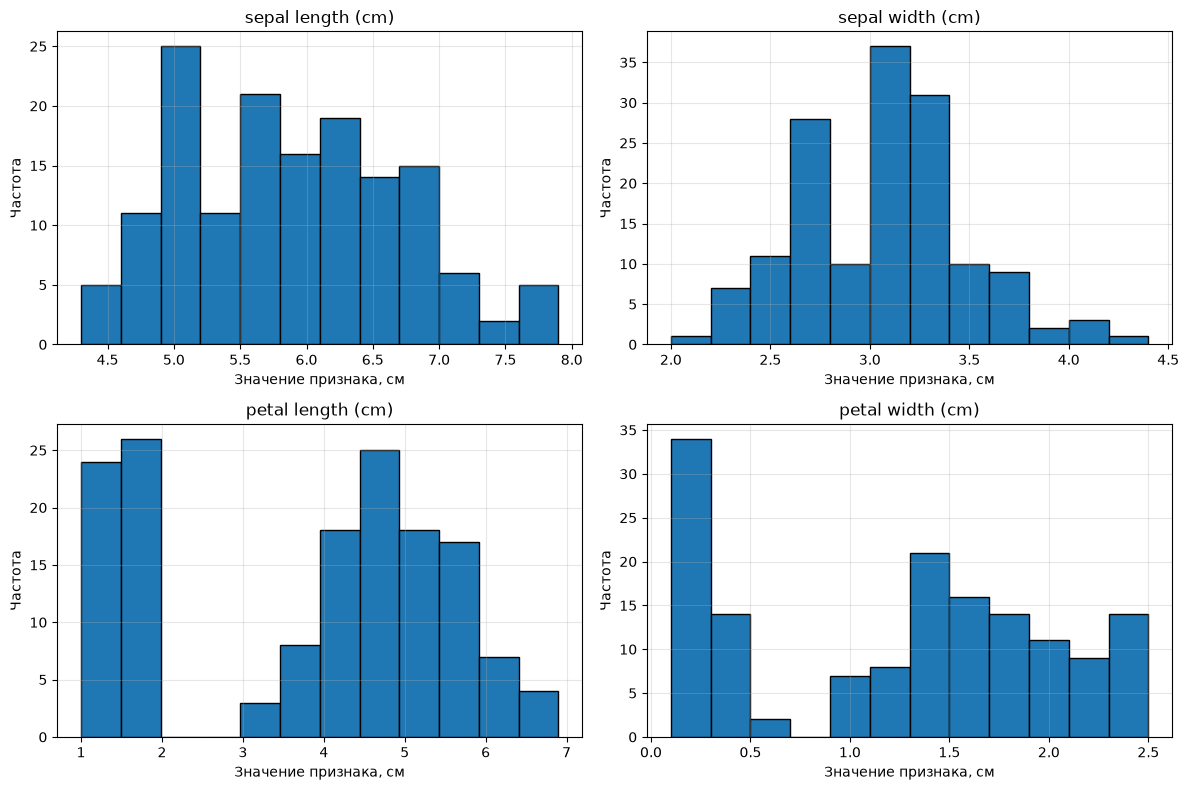

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flatten(), iris_pd.columns):
    ax.hist(
        iris_pd[col],
        bins=12,
        edgecolor="black"
    )

    ax.set_title(col)
    ax.set_xlabel("Значение признака, см")
    ax.set_ylabel("Частота")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [10]:
variation = pd.DataFrame({
    "Среднее": iris_pd.mean(),
    "СКО": iris_pd.std(),
    "Коэффициент вариации (%)":
        iris_pd.std() / iris_pd.mean().abs() * 100
})

display(variation.round(3))

,Среднее,СКО,Коэффициент вариации (%)
sepal length (cm),5.843,0.828,14.171
sepal width (cm),3.057,0.436,14.256
petal length (cm),3.758,1.765,46.974
petal width (cm),1.199,0.762,63.555


## Часть 2. Парная и множественная регрессия

In [11]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score


x1 = iris_pd["sepal length (cm)"]
x2 = iris_pd["sepal width (cm)"]
x3 = iris_pd["petal length (cm)"]
y = iris_pd["petal width (cm)"]


X_pair = iris_pd[["petal length (cm)"]]


X_multiple = iris_pd[["sepal length (cm)", "sepal width (cm)","petal length (cm)"]]

print("Размер парной выборки:", X_pair.shape)
print("Размер множественной выборки:", X_multiple.shape)
print("Размер выходной переменной:", y.shape)

Размер парной выборки: (150, 1)
Размер множественной выборки: (150, 3)
Размер выходной переменной: (150,)


In [12]:
# Создаём модель парной регрессии
pair_model = LinearRegression()

# Обучаем модель
pair_model.fit(X_pair, y)

# Получаем предсказанные значения
y_pred_pair = pair_model.predict(X_pair)

# Коэффициенты уравнения
b0_pair = pair_model.intercept_
b1_pair = pair_model.coef_[0]

print("Уравнение парной регрессии:")
print(f"Y = {b0_pair:.4f} + ({b1_pair:.4f}) * X3")

Уравнение парной регрессии:
Y = -0.3631 + (0.4158) * X3


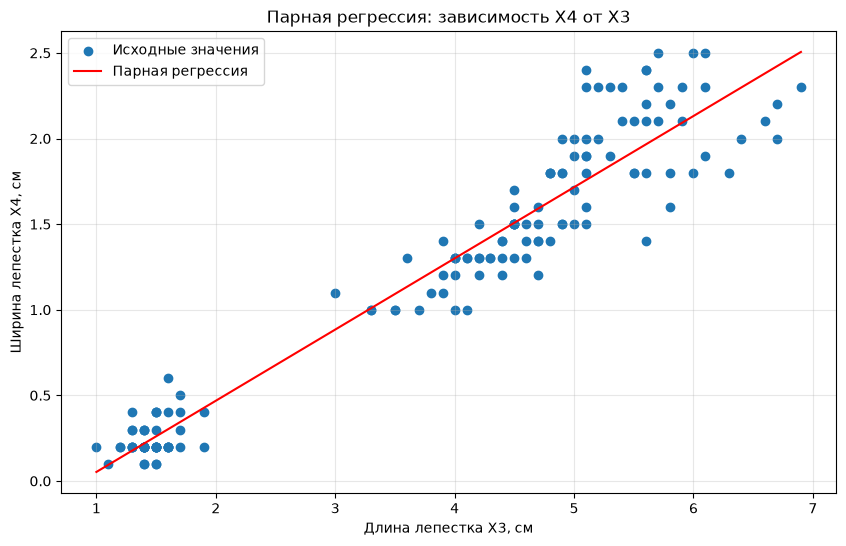

In [13]:
plt.figure(figsize=(10, 6))

plt.scatter(x3, y, label="Исходные значения")

# Сортируем X для правильного отображения линии
order = np.argsort(x3.to_numpy())

plt.plot(
    x3.to_numpy()[order],
    y_pred_pair[order],
    color="red",
    label="Парная регрессия"
)

plt.title("Парная регрессия: зависимость X4 от X3")
plt.xlabel("Длина лепестка X3, см")
plt.ylabel("Ширина лепестка X4, см")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [14]:
# Создаём модель множественной регрессии
multiple_model = LinearRegression()

# Обучение
multiple_model.fit(X_multiple, y)

# Предсказание
y_pred_multiple = multiple_model.predict(X_multiple)

# Коэффициенты
b0 = multiple_model.intercept_
b1, b2, b3 = multiple_model.coef_

print("Уравнение множественной регрессии:")
print(
    f"Y = {b0:.4f} "
    f"+ ({b1:.4f}) * X1 "
    f"+ ({b2:.4f}) * X2 "
    f"+ ({b3:.4f}) * X3"
)

Уравнение множественной регрессии:
Y = -0.2403 + (-0.2073) * X1 + (0.2228) * X2 + (0.5241) * X3


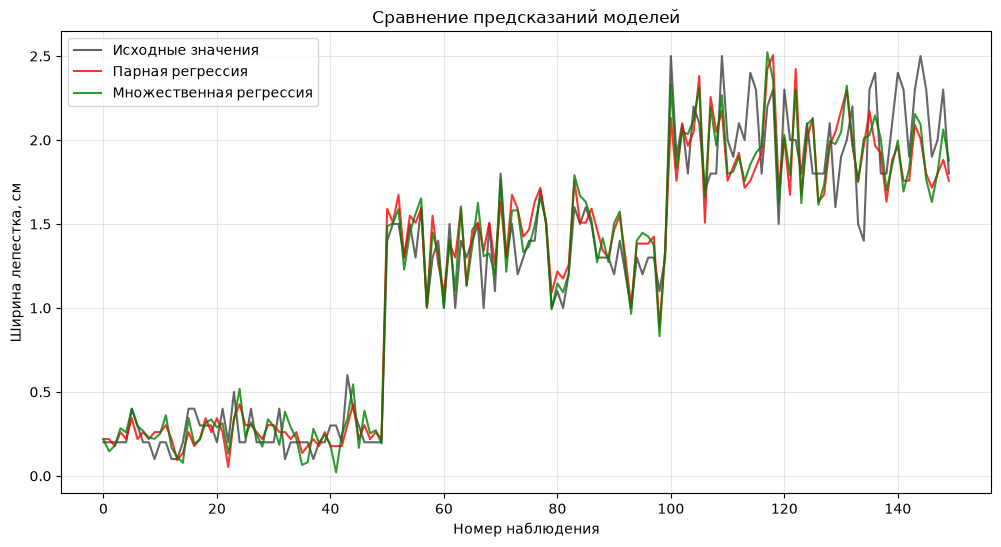

In [15]:
plt.figure(figsize=(12, 6))

# Номера наблюдений
n = np.arange(len(y))

# Реальные значения
plt.plot(
    n, y,
    color="black",
    label="Исходные значения",
    alpha=0.6
)

# Предсказания парной регрессии
plt.plot(
    n, y_pred_pair,
    color="red",
    label="Парная регрессия",
    alpha=0.8
)

# Предсказания множественной регрессии
plt.plot(
    n, y_pred_multiple,
    color="green",
    label="Множественная регрессия",
    alpha=0.8
)

plt.title("Сравнение предсказаний моделей")
plt.xlabel("Номер наблюдения")
plt.ylabel("Ширина лепестка, см")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

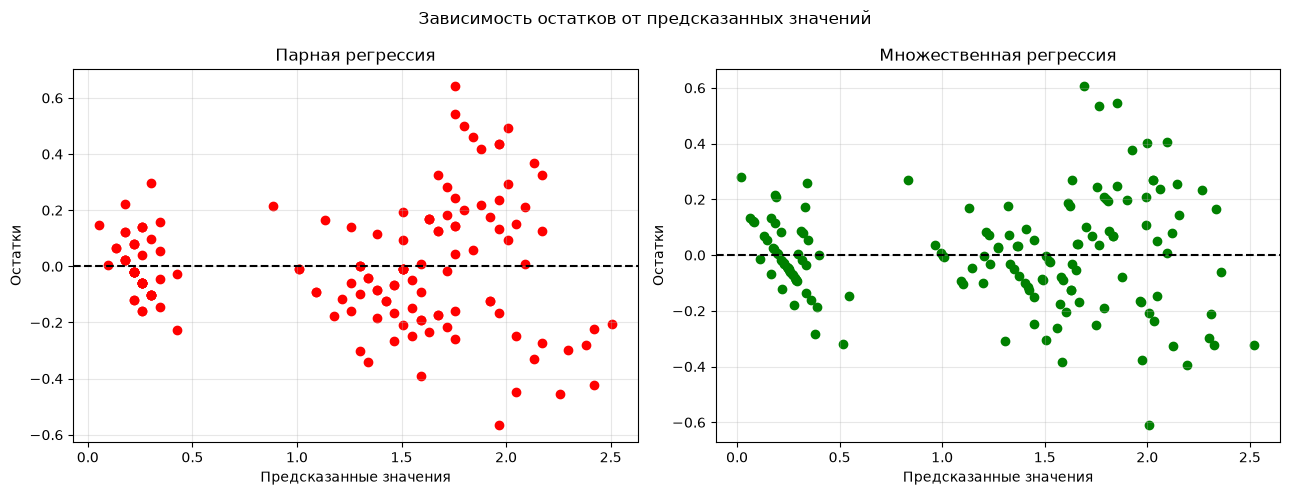

In [16]:
# Остатки парной регрессии
residuals_pair = y.to_numpy() - y_pred_pair

# Остатки множественной регрессии
residuals_multiple = y.to_numpy() - y_pred_multiple

# Один рисунок с двумя графиками
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Парная регрессия
axes[0].scatter(
    y_pred_pair,
    residuals_pair,
    color="red"
)
axes[0].axhline(0, color="black", linestyle="--")
axes[0].set_title("Парная регрессия")
axes[0].set_xlabel("Предсказанные значения")
axes[0].set_ylabel("Остатки")
axes[0].grid(alpha=0.3)

# Множественная регрессия
axes[1].scatter(
    y_pred_multiple,
    residuals_multiple,
    color="green"
)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set_title("Множественная регрессия")
axes[1].set_xlabel("Предсказанные значения")
axes[1].set_ylabel("Остатки")
axes[1].grid(alpha=0.3)

plt.suptitle("Зависимость остатков от предсказанных значений")
plt.tight_layout()
plt.show()

In [17]:
def regression_metrics(y_true, y_pred, p):
    n = len(y_true)

    # Коэффициент детерминации
    r2 = r2_score(y_true, y_pred)

    # Скорректированный R²
    r2_adj = 1 - (1 - r2) * (n - 1) / (n - p - 1)

    # Сумма квадратов остатков
    sse = np.sum((np.asarray(y_true) - y_pred) ** 2)

    # Стандартная ошибка регрессии
    standard_error = np.sqrt(sse / (n - p - 1))

    # Множественный коэффициент корреляции
    r = np.sqrt(r2)

    return {
        "R": r,
        "R²": r2,
        "Скорректированный R²": r2_adj,
        "Стандартная ошибка": standard_error
    }


# Парная регрессия: один входной признак
metrics_pair = regression_metrics(y, y_pred_pair, p=1)

# Множественная регрессия: три входных признака
metrics_multiple = regression_metrics(y, y_pred_multiple, p=3)

comparison = pd.DataFrame({
    "Парная регрессия": metrics_pair,
    "Множественная регрессия": metrics_multiple
})

display(comparison.round(4))

,Парная регрессия,Множественная регрессия
R,0.9629,0.9684
R²,0.9271,0.9379
Скорректированный R²,0.9266,0.9366
Стандартная ошибка,0.2065,0.1920


## Часть 3. Анализ остатков (нормальность, автокорреляция)

In [18]:
# Проверяем основные характеристики остатков

residuals_df = pd.DataFrame({
    "Парная регрессия": residuals_pair,
    "Множественная регрессия": residuals_multiple
})

display(residuals_df.describe())

,Парная регрессия,Множественная регрессия
count,1.500000e+02,1.500000e+02
mean,-1.006602e-16,1.776357e-16
std,2.057903e-01,1.900247e-01
min,-5.651548e-01,-6.095892e-01
25%,-1.235793e-01,-1.013411e-01
50%,-1.898206e-02,-1.088859e-02
75%,1.328758e-01,9.825006e-02
max,6.427229e-01,6.068509e-01


In [19]:
from scipy import stats

print("Критерий Колмогорова-Смирнова")
print("Уровень значимости α = 0.05\n")

for name, residuals in residuals_df.items():

    # Среднее и выборочное СКО
    mean = np.mean(residuals)
    std = np.std(residuals, ddof=1)

    # Стандартизация остатков
    residuals_std = (residuals - mean) / std

    # Критерий Колмогорова-Смирнова
    statistic, pvalue = stats.kstest(
        residuals_std,
        "norm",
        alternative="two-sided"
    )

    if pvalue > 0.05:
        result = "H0 не отвергается"
    else:
        result = "H0 отвергается"

    print(name)
    print(f"Статистика D = {statistic:.4f}")
    print(f"p-value = {pvalue:.4f}")
    print(f"Вывод: {result}\n")

Критерий Колмогорова-Смирнова
Уровень значимости α = 0.05

Парная регрессия
Статистика D = 0.0830
p-value = 0.2397
Вывод: H0 не отвергается

Множественная регрессия
Статистика D = 0.0625
p-value = 0.5787
Вывод: H0 не отвергается



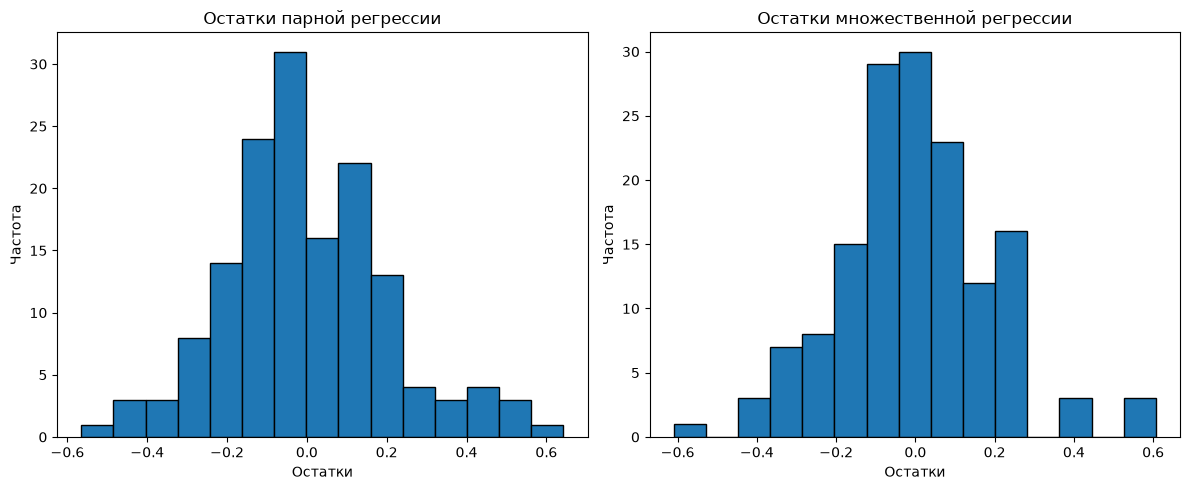

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(
    residuals_pair,
    bins=15,
    edgecolor="black"
)
axes[0].set_title("Остатки парной регрессии")
axes[0].set_xlabel("Остатки")
axes[0].set_ylabel("Частота")

axes[1].hist(
    residuals_multiple,
    bins=15,
    edgecolor="black"
)
axes[1].set_title("Остатки множественной регрессии")
axes[1].set_xlabel("Остатки")
axes[1].set_ylabel("Частота")

plt.tight_layout()
plt.show()

In [21]:
def calculate_dw(residuals):
    residuals = np.asarray(residuals)
    numerator = np.sum(np.diff(residuals) ** 2)
    denominator = np.sum(residuals ** 2)
    return numerator / denominator

print("Парная:", calculate_dw(residuals_pair))
print("Множественная:", calculate_dw(residuals_multiple))

Парная: 1.4549102947770671
Множественная: 1.5730087602884457


In [22]:
alpha = 0.05

results = []

models = {
    "Парная регрессия": residuals_pair,
    "Множественная регрессия": residuals_multiple
}

for name, residuals in models.items():

    # Стандартизация остатков
    mean = np.mean(residuals)
    std = np.std(residuals, ddof=1)
    residuals_std = (residuals - mean) / std

    # Критерий Колмогорова-Смирнова
    statistic, pvalue = stats.kstest(
        residuals_std,
        "norm",
        alternative="two-sided"
    )

    # Статистика Дурбина-Уотсона
    dw = calculate_dw(residuals)

    # Проверка гипотезы о нормальности
    if pvalue > alpha:
        normality = "H0 не отвергается"
    else:
        normality = "H0 отвергается"

    # Предварительная интерпретация DW
    if dw < 2:
        dw_result = "Возможна положительная автокорреляция"
    elif dw > 2:
        dw_result = "Возможна отрицательная автокорреляция"
    else:
        dw_result = "DW = 2"

    results.append({
        "Модель": name,
        "Статистика D": statistic,
        "p-value": pvalue,
        "Вывод по H0": normality,
        "DW": dw,
        "Вывод по DW": dw_result
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Модель,Статистика D,p-value,Вывод по H0,DW,Вывод по DW
0,Парная регрессия,0.0830,0.2397,H0 не отвергается,1.4549,Возможна положительная автокорреляция
1,Множественная регрессия,0.0625,0.5787,H0 не отвергается,1.5730,Возможна положительная автокорреляция


## Часть 4. Анализ выбросов

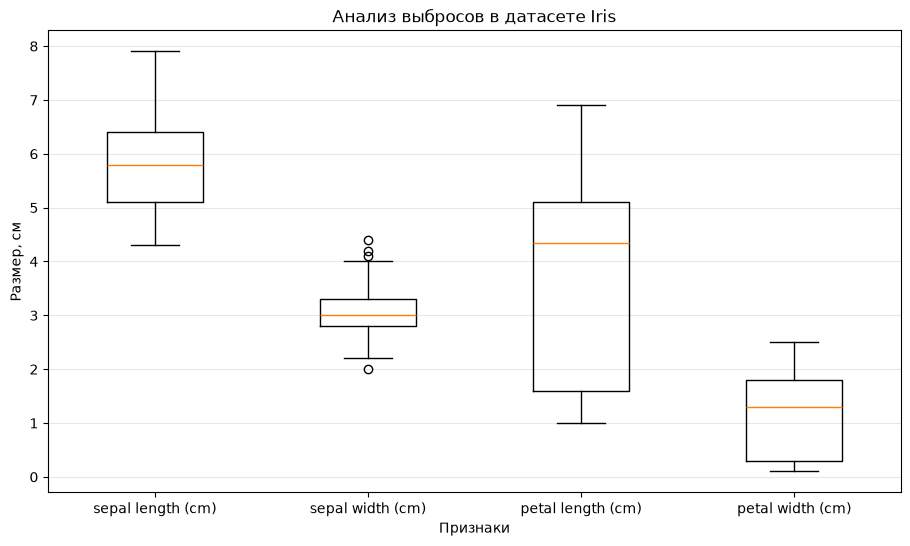

In [23]:
plt.figure(figsize=(11, 6))

plt.boxplot(
    iris_pd.to_numpy(),
    tick_labels=iris_pd.columns
)

plt.title("Анализ выбросов в датасете Iris")
plt.xlabel("Признаки")
plt.ylabel("Размер, см")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [24]:
outliers_results = []

for col in iris_pd.columns:

    # Первый и третий квартили
    q1 = iris_pd[col].quantile(0.25)
    q3 = iris_pd[col].quantile(0.75)

    # Межквартильный размах
    iqr = q3 - q1

    # Границы выбросов
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    # Определение выбросов
    outliers = iris_pd[
        (iris_pd[col] < lower) |
        (iris_pd[col] > upper)
    ]

    outliers_results.append({
        "Признак": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Нижняя граница": lower,
        "Верхняя граница": upper,
        "Количество выбросов": len(outliers)
    })

outliers_df = pd.DataFrame(outliers_results)

display(outliers_df.round(3))

,Признак,Q1,Q3,IQR,Нижняя граница,Верхняя граница,Количество выбросов
0,sepal length (cm),5.1,6.4,1.3,3.15,8.35,0
1,sepal width (cm),2.8,3.3,0.5,2.05,4.05,4
2,petal length (cm),1.6,5.1,3.5,-3.65,10.35,0
3,petal width (cm),0.3,1.8,1.5,-1.95,4.05,0


In [25]:
for col in iris_pd.columns:

    q1 = iris_pd[col].quantile(0.25)
    q3 = iris_pd[col].quantile(0.75)

    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = iris_pd.loc[
        (iris_pd[col] < lower) |
        (iris_pd[col] > upper),
        col
    ]

    print(f"\nПризнак: {col}")
    print("Значения выбросов:", outliers.to_list())


Признак: sepal length (cm)
Значения выбросов: []

Признак: sepal width (cm)
Значения выбросов: [4.4, 4.1, 4.2, 2.0]

Признак: petal length (cm)
Значения выбросов: []

Признак: petal width (cm)
Значения выбросов: []


## Часть 5. Предсказание и оценка точности (train/test)

In [26]:
from sklearn.model_selection import train_test_split

# Входные переменные
X = iris_pd[
    ["sepal length (cm)",
     "sepal width (cm)",
     "petal length (cm)"]
]

# Выходная переменная
y = iris_pd["petal width (cm)"]

# Разделение выборки
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)

print("Размер обучающей выборки:", X_train.shape)
print("Размер тестовой выборки:", X_test.shape)

Размер обучающей выборки: (112, 3)
Размер тестовой выборки: (38, 3)


In [32]:


# Создание модели
model_test = LinearRegression()

# Обучение на 75% выборки
model_test.fit(X_train, y_train)

# Предсказания на тестовой выборке
y_pred_test = model_test.predict(X_test)

print("Коэффициенты модели:")
print("b0 =", model_test.intercept_)
print("b1, b2, b3 =", model_test.coef_)

Коэффициенты модели:
b0 = -0.14916391036571497
b1, b2, b3 = [-0.24488106  0.24482729  0.53764071]


In [33]:
from sklearn.metrics import mean_squared_error, r2_score

# Среднеквадратическая ошибка
mse = mean_squared_error(y_test, y_pred_test)

# Корень из среднеквадратической ошибки
rmse = np.sqrt(mse)

# Коэффициент детерминации
r2 = r2_score(y_test, y_pred_test)

print(f"MSE: {mse:.4f}")
print(f"СКО (RMSE): {rmse:.4f} см")
print(f"Коэффициент детерминации R²: {r2:.4f}")

MSE: 0.0405
СКО (RMSE): 0.2012 см
Коэффициент детерминации R²: 0.9369


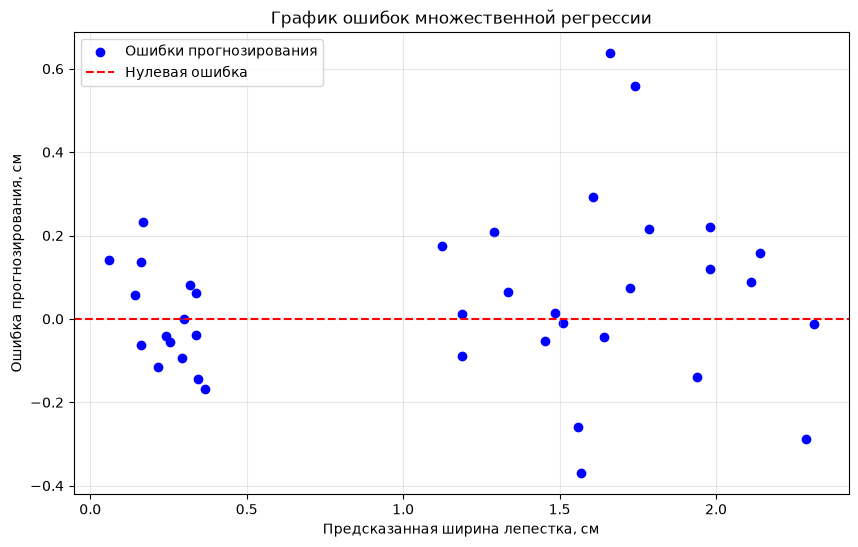

In [34]:
# Ошибки на тестовой выборке
errors = y_test.to_numpy() - y_pred_test

plt.figure(figsize=(10, 6))

plt.scatter(
    y_pred_test,
    errors,
    color="blue",
    label="Ошибки прогнозирования"
)

# Горизонтальная линия нулевой ошибки
plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Нулевая ошибка"
)

plt.title("График ошибок множественной регрессии")
plt.xlabel("Предсказанная ширина лепестка, см")
plt.ylabel("Ошибка прогнозирования, см")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

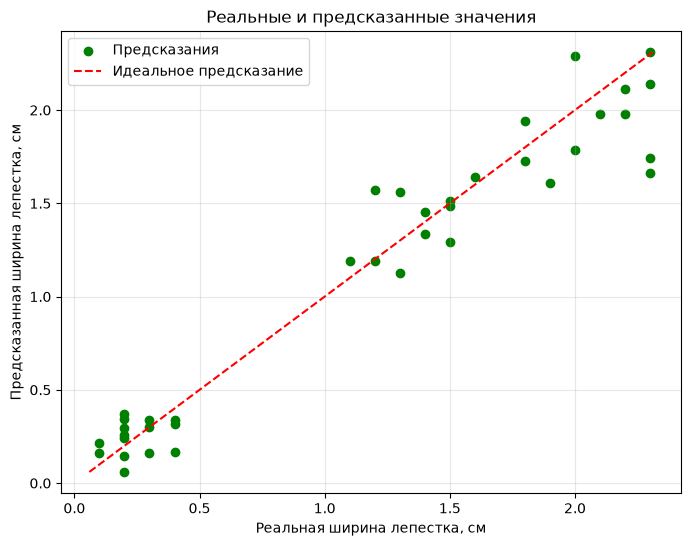

In [35]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_test,
    color="green",
    label="Предсказания"
)

# Линия идеального совпадения
min_value = min(y_test.min(), y_pred_test.min())
max_value = max(y_test.max(), y_pred_test.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    color="red",
    linestyle="--",
    label="Идеальное предсказание"
)

plt.title("Реальные и предсказанные значения")
plt.xlabel("Реальная ширина лепестка, см")
plt.ylabel("Предсказанная ширина лепестка, см")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Часть 6. Исследование: как меняется регрессия после удаления выбросов

Удалено выбросов: 4 из 150
До:    R^2=0.9379, adj R^2=0.9366
После: R^2=0.9368, adj R^2=0.9355
Коэфф. до:     b0=-0.240 [-0.207, 0.223, 0.524]
Коэфф. после: b0=-0.270 [-0.211, 0.238, 0.525]


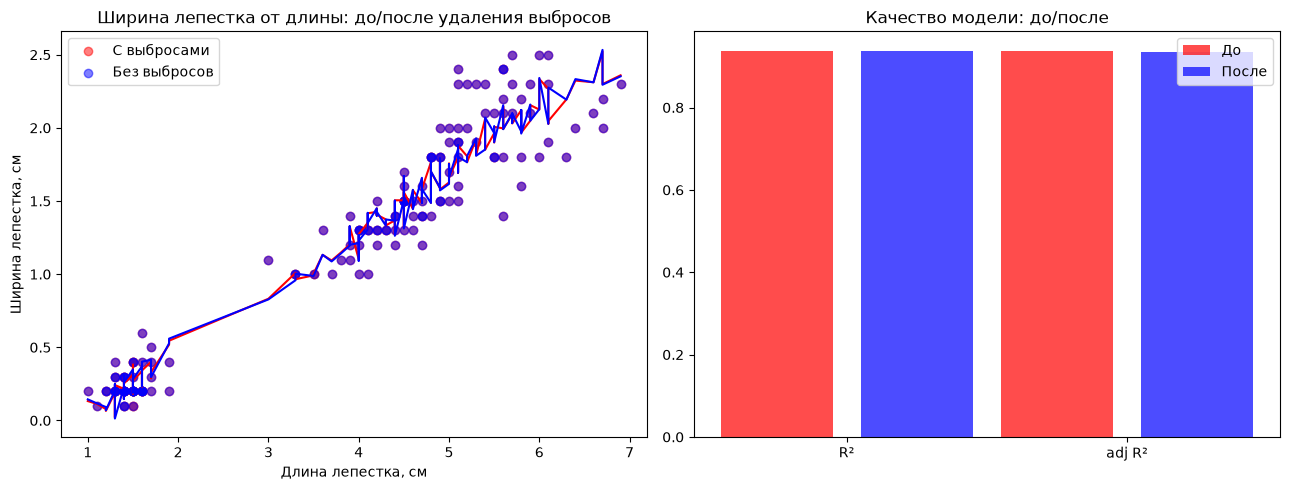

In [36]:

# Вычисляем маску выбросов по методу IQR по входным признакам
def _iqr_mask(frame, cols):
    m = pd.Series(False, index=frame.index)
    for c in cols:
        q1, q3 = frame[c].quantile(0.25), frame[c].quantile(0.75)
        iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        m = m | ((frame[c] < lo) | (frame[c] > hi))
    return m


# Зависимая и независимые переменные
y_name = "petal width (cm)"

x_cols = [
    "sepal length (cm)",
    "sepal width (cm)",
    "petal length (cm)"
]

# Определяем выбросы
mask = _iqr_mask(iris_pd, x_cols)

# Создаём выборку без выбросов
df_clean = iris_pd.loc[~mask].copy()


# Функция обучения и оценки регрессии
def _score(d, xc):
    m = LinearRegression().fit(d[xc], d[y_name])
    r2 = r2_score(d[y_name], m.predict(d[xc]))
    n, p = len(d), len(xc)

    return m, r2, 1 - (1 - r2) * (n - 1) / (n - p - 1)


# Обучаем модели до и после удаления выбросов
m_full, r2_full, adj_full = _score(iris_pd, x_cols)
m_cln, r2_cln, adj_cln = _score(df_clean, x_cols)


# Выводим результаты
print("Удалено выбросов:", int(mask.sum()), "из", len(iris_pd))

print(f"До:    R^2={r2_full:.4f}, adj R^2={adj_full:.4f}")
print(f"После: R^2={r2_cln:.4f}, adj R^2={adj_cln:.4f}")

print(
    "Коэфф. до:     b0=%.3f" % m_full.intercept_,
    [round(float(v), 3) for v in m_full.coef_]
)

print(
    "Коэфф. после: b0=%.3f" % m_cln.intercept_,
    [round(float(v), 3) for v in m_cln.coef_]
)


# Строим графики
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for d, m, colr, lab in [
    (iris_pd, m_full, "red", "С выбросами"),
    (df_clean, m_cln, "blue", "Без выбросов")
]:

    axes[0].scatter(
        d["petal length (cm)"],
        d[y_name],
        color=colr,
        alpha=0.5,
        label=lab
    )

    oo = np.argsort(d["petal length (cm)"].to_numpy())

    axes[0].plot(
        d["petal length (cm)"].to_numpy()[oo],
        m.predict(d[x_cols].iloc[oo]),
        color=colr
    )


axes[0].set_title("Ширина лепестка от длины: до/после удаления выбросов")
axes[0].set_xlabel("Длина лепестка, см")
axes[0].set_ylabel("Ширина лепестка, см")
axes[0].legend()


# Сравнение R² и скорректированного R²
axes[1].bar(
    [0, 1],
    [r2_full, adj_full],
    color="red",
    alpha=0.7,
    label="До",
    width=0.4
)

axes[1].bar(
    [0.5, 1.5],
    [r2_cln, adj_cln],
    color="blue",
    alpha=0.7,
    label="После",
    width=0.4
)

axes[1].set_xticks([0.25, 1.25])
axes[1].set_xticklabels(["R²", "adj R²"])
axes[1].set_title("Качество модели: до/после")
axes[1].legend()

plt.tight_layout()
plt.show()


## Часть 7. Предложения по улучшению регрессионной модели

In [37]:
print("""
1. Исследовать влияние выбросов: проверить изменение коэффициентов и точности регрессии после обработки выбросов признака sepal width (cm).
2. Проверить мультиколлинеарность (VIF) между независимыми переменными, особенно sepal length (cm) и petal length (cm), для которых r = 0.872.
3. Попробовать нелинейные модели (полиномиальная регрессия, градиентный бустинг).
4. Применить кросс-валидацию для более надёжной оценки точности модели на разных разбиениях выборки.
5. Исследовать регрессионные зависимости отдельно для каждого вида ирисов и сравнить качество полученных моделей.
""")


1. Исследовать влияние выбросов: проверить изменение коэффициентов и точности регрессии после обработки выбросов признака sepal width (cm).
2. Проверить мультиколлинеарность (VIF) между независимыми переменными, особенно sepal length (cm) и petal length (cm), для которых r = 0.872.
3. Попробовать нелинейные модели (полиномиальная регрессия, градиентный бустинг).
4. Применить кросс-валидацию для более надёжной оценки точности модели на разных разбиениях выборки.
5. Исследовать регрессионные зависимости отдельно для каждого вида ирисов и сравнить качество полученных моделей.

